In [3]:
import os

import matplotlib.pyplot as plt
import numpy as np
import scanpy as sc

print(os.getcwd())

/home/leo/proyectos/scrnaseq-fastq-to-matrix/notebooks


In [4]:
RAIZ = ".." 
RUTA_ADATA = f"{RAIZ}/data/processed/pbmc_1k_v3/counts_unfiltered/adata.h5ad"
RUTA_FIGURA = f"{RAIZ}/results/figures/knee_plot.png"
RUTA_FILTRADA = f"{RAIZ}/data/processed/pbmc_1k_v3/adata_filtered.h5ad"

adata = sc.read_h5ad(RUTA_ADATA)
adata

AnnData object with n_obs × n_vars = 241214 × 39546

In [5]:
print(type(adata.X))
print(adata.obs_names[:3])  # barcodes (filas)
print(adata.var_names[:3])  # genes (columnas)

# Proporción de valores distintos de cero
n_total = adata.n_obs * adata.n_vars
print(f"Valores distintos de cero: {adata.X.nnz:,} de {n_total:,} ({adata.X.nnz / n_total:.4%})")

<class 'scipy.sparse._csr.csr_matrix'>
Index(['AAACCCAAGAAACTCA', 'AAACCCAAGAAATTCG', 'AAACCCAAGAAGAGTA'], dtype='object', name='barcode')
Index(['ENSG00000160072.20', 'ENSG00000228037.1', 'ENSG00000142611.17'], dtype='object', name='gene_id')
Valores distintos de cero: 3,531,657 de 9,539,048,844 (0.0370%)


In [6]:
# Suma de cada fila; la suma de una matriz dispersa da una matriz de 1 columna, por eso ravel()
adata.obs["n_umis"] = np.asarray(adata.X.sum(axis=1)).ravel()
adata.obs["n_umis"].describe()

count    241214.000000
mean         43.674770
std         661.840376
min           0.000000
25%           1.000000
50%           2.000000
75%           6.000000
max       59111.000000
Name: n_umis, dtype: float64

In [7]:
umis_ordenados = np.sort(adata.obs["n_umis"].to_numpy())[::-1]
rango = np.arange(1, len(umis_ordenados) + 1)

print(umis_ordenados[:5])  # los 5 barcodes con más UMIs

[59111. 54615. 47268. 37665. 33316.]


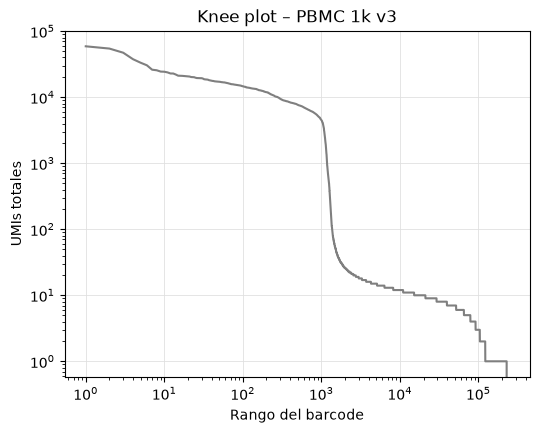

In [8]:
fig, ax = plt.subplots(figsize=(6, 4.5))
ax.plot(rango, umis_ordenados, color="#7f7f7f", linewidth=1.5)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Rango del barcode")
ax.set_ylabel("UMIs totales")
ax.set_title("Knee plot – PBMC 1k v3")
ax.grid(True, which="major", color="#e0e0e0", linewidth=0.6)
plt.show()

In [9]:
print(f"UMIs del barcode en el rango 1,222: {umis_ordenados[1221]:.0f}")  # Python cuenta desde 0

for umbral in [100, 200, 500, 1000, 2000]:
    n = (adata.obs["n_umis"] >= umbral).sum()
    print(f"≥ {umbral:>5} UMIs: {n:>6,} barcodes")

UMIs del barcode en el rango 1,222: 661
≥   100 UMIs:  1,369 barcodes
≥   200 UMIs:  1,315 barcodes
≥   500 UMIs:  1,251 barcodes
≥  1000 UMIs:  1,177 barcodes
≥  2000 UMIs:  1,131 barcodes


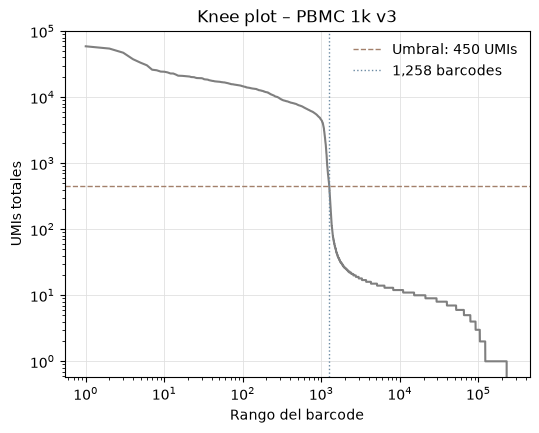

In [21]:
UMBRAL = 450 # ajústalo según lo que viste en la gráfica y en la celda anterior

n_celulas = int((adata.obs["n_umis"] >= UMBRAL).sum())

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.plot(rango, umis_ordenados, color="#7f7f7f", linewidth=1.5)
ax.axhline(UMBRAL, color="#a3806b", linestyle="--", linewidth=1, label=f"Umbral: {UMBRAL} UMIs")
ax.axvline(n_celulas, color="#6b8aa3", linestyle=":", linewidth=1, label=f"{n_celulas:,} barcodes")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Rango del barcode")
ax.set_ylabel("UMIs totales")
ax.set_title("Knee plot – PBMC 1k v3")
ax.grid(True, which="major", color="#e0e0e0", linewidth=0.6)
ax.legend(frameon=False)
plt.show()

In [22]:
adata_filtrada = adata[adata.obs["n_umis"] >= UMBRAL].copy()

eliminados = adata.n_obs - adata_filtrada.n_obs
print(f"Células retenidas: {adata_filtrada.n_obs:,}")
print(f"Barcodes eliminados: {eliminados:,} ({eliminados / adata.n_obs:.1%})")

fig.savefig(RUTA_FIGURA, dpi=150, bbox_inches="tight")
adata_filtrada.write_h5ad(RUTA_FILTRADA)

Células retenidas: 1,258
Barcodes eliminados: 239,956 (99.5%)
